In [31]:
import pandas as pd
df = pd.read_csv('train.csv')
df.head()

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


In [32]:
df.shape

(21263, 82)

In [33]:
df.dtypes.value_counts()

float64    79
int64       3
Name: count, dtype: int64

In [34]:
df.isnull().sum()

number_of_elements       0
mean_atomic_mass         0
wtd_mean_atomic_mass     0
gmean_atomic_mass        0
wtd_gmean_atomic_mass    0
                        ..
range_Valence            0
wtd_range_Valence        0
std_Valence              0
wtd_std_Valence          0
critical_temp            0
Length: 82, dtype: int64

In [35]:
df.isnull().sum().sum()

np.int64(0)

In [36]:
df.duplicated().sum()

np.int64(66)

In [37]:
df['critical_temp'].describe()

count    21263.000000
mean        34.421219
std         34.254362
min          0.000210
25%          5.365000
50%         20.000000
75%         63.000000
max        185.000000
Name: critical_temp, dtype: float64

In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21263 entries, 0 to 21262
Data columns (total 82 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   number_of_elements               21263 non-null  int64  
 1   mean_atomic_mass                 21263 non-null  float64
 2   wtd_mean_atomic_mass             21263 non-null  float64
 3   gmean_atomic_mass                21263 non-null  float64
 4   wtd_gmean_atomic_mass            21263 non-null  float64
 5   entropy_atomic_mass              21263 non-null  float64
 6   wtd_entropy_atomic_mass          21263 non-null  float64
 7   range_atomic_mass                21263 non-null  float64
 8   wtd_range_atomic_mass            21263 non-null  float64
 9   std_atomic_mass                  21263 non-null  float64
 10  wtd_std_atomic_mass              21263 non-null  float64
 11  mean_fie                         21263 non-null  float64
 12  wtd_mean_fie                 

In [39]:
df_clean = df.drop_duplicates()
print("Before: ", df.shape)
print("After: ", df_clean.shape)
print("Rows removed: ", df.shape[0] - df_clean.shape[0])

Before:  (21263, 82)
After:  (21197, 82)
Rows removed:  66


In [40]:
X = df_clean.drop(columns='critical_temp')
y = df_clean['critical_temp']

print("X shape: ", X.shape)
print("y shape: ", y.shape)

X shape:  (21197, 81)
y shape:  (21197,)


In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train: ", X_train.shape, " Test: ", X_test.shape)

Train:  (16957, 81)  Test:  (4240, 81)


In [42]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:24s}  RMSE={rmse:6.2f}   MAE={mae:6.2f}   R2={r2:6.3f}")
    return {"model": name, "rmse": rmse, "mae": mae, "r2": r2}

results = []

In [43]:
from sklearn.dummy import DummyRegressor

dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

results.append(evaluate('DummyRegressor (Mean)', y_test, y_pred_dummy))

DummyRegressor (Mean)     RMSE= 34.31   MAE= 29.36   R2=-0.000


In [44]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

linreg = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

linreg.fit(X_train, y_train)
y_pred_lin = linreg.predict(X_test)

results.append(evaluate('LinearRegression', y_test, y_pred_lin))

LinearRegression          RMSE= 17.65   MAE= 13.27   R2= 0.735


In [45]:
coefs = linreg.named_steps["model"].coef_
print("--- coefficient sanity check ---")
print(f"Number of coefficients : {len(coefs)}")
print(f"Largest |coef|         : {np.abs(coefs).max():8.1f}")
print(f"Mean |coef|            : {np.abs(coefs).mean():8.1f}")
print(f"Coefs with |value| > 50: {(np.abs(coefs) > 50).sum()}")

--- coefficient sanity check ---
Number of coefficients : 81
Largest |coef|         :     99.4
Mean |coef|            :     14.6
Coefs with |value| > 50: 2


In [46]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

alphas = [0.1, 1.0, 10.0, 100.0]

print("--- 5-fold CV (RMSE) to choose alpha ---")

for a in alphas:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=a))
    ])

    cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')

    print(f"alpha={a:7.1f}   CV RMSE = {-cv_scores.mean():.3f}  (+/- {cv_scores.std():.3f})")

--- 5-fold CV (RMSE) to choose alpha ---
alpha=    0.1   CV RMSE = 17.658  (+/- 0.213)
alpha=    1.0   CV RMSE = 17.668  (+/- 0.208)
alpha=   10.0   CV RMSE = 17.732  (+/- 0.209)
alpha=  100.0   CV RMSE = 18.113  (+/- 0.211)


In [47]:
best_alpha = 1.0

ridge = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge(alpha=best_alpha))
])

ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)

results.append(evaluate(f'Ridge (alpha={best_alpha})', y_test, y_pred_ridge))

Ridge (alpha=1.0)         RMSE= 17.66   MAE= 13.27   R2= 0.735


In [48]:
coefs = ridge.named_steps["model"].coef_
print("--- coefficient sanity check ---")
print(f"Largest |coef|         : {np.abs(coefs).max():8.1f}")
print(f"Mean |coef|            : {np.abs(coefs).mean():8.1f}")
print(f"Coefs with |value| > 50: {(np.abs(coefs) > 50).sum()}")

--- coefficient sanity check ---
Largest |coef|         :     62.0
Mean |coef|            :     11.4
Coefs with |value| > 50: 2


In [49]:
from sklearn.linear_model import Lasso

alphas = [0.001, 0.01, 0.1, 1.0]

print("--- 5-fold CV (RMSE) to choose alpha ---")

for a in alphas:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=a, max_iter=100000))
    ])

    cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')

    print(f"alpha={a:7.3f}   CV RMSE = {-cv_scores.mean():.3f}  (+/- {cv_scores.std():.3f})")

--- 5-fold CV (RMSE) to choose alpha ---
alpha=  0.001   CV RMSE = 17.662  (+/- 0.210)
alpha=  0.010   CV RMSE = 17.726  (+/- 0.206)
alpha=  0.100   CV RMSE = 18.468  (+/- 0.228)
alpha=  1.000   CV RMSE = 20.291  (+/- 0.172)


In [50]:
best_alpha = 0.01

lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=best_alpha, max_iter=100000)),
])

lasso.fit(X_train, y_train)
y_pred_lasso = lasso.predict(X_test)
results.append(evaluate(f"Lasso (alpha={best_alpha})", y_test, y_pred_lasso))

Lasso (alpha=0.01)        RMSE= 17.75   MAE= 13.32   R2= 0.732


In [51]:
coefs = lasso.named_steps["model"].coef_
n_zero = (coefs == 0).sum()
print("\n--- coefficient sanity check ---")
print(f"Largest |coef|         : {np.abs(coefs).max():8.1f}")
print(f"Mean |coef|            : {np.abs(coefs).mean():8.1f}")
print(f"Features kept (nonzero): {(coefs != 0).sum()} / {len(coefs)}")
print(f"Features dropped (zero): {n_zero}")


--- coefficient sanity check ---
Largest |coef|         :     47.2
Mean |coef|            :      7.2
Features kept (nonzero): 69 / 81
Features dropped (zero): 12


In [52]:
from sklearn.linear_model import ElasticNet

alphas = [0.001, 0.01, 0.1]
l1_ratios = [0.2, 0.5, 0.8]

print("--- 5-fold CV (RMSE) over the alpha x l1_ratio grid ---")
best = {"rmse": np.inf, "alpha": None, "l1_ratio": None}
for a in alphas:
    for r in l1_ratios:
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("model", ElasticNet(alpha=a, l1_ratio=r, max_iter=100000)),
        ])
        cv_scores = cross_val_score(
            pipe, X_train, y_train,
            cv=5, scoring="neg_root_mean_squared_error"
        )
        rmse = -cv_scores.mean()
        print(f"alpha={a:6.3f}  l1_ratio={r:.1f}   CV RMSE = {rmse:.3f}  (+/- {cv_scores.std():.3f})")
        if rmse < best["rmse"]:
            best = {"rmse": rmse, "alpha": a, "l1_ratio": r}

print(f"\nBest by CV: alpha={best['alpha']}, l1_ratio={best['l1_ratio']}  (RMSE {best['rmse']:.3f})")

--- 5-fold CV (RMSE) over the alpha x l1_ratio grid ---
alpha= 0.001  l1_ratio=0.2   CV RMSE = 17.738  (+/- 0.210)
alpha= 0.001  l1_ratio=0.5   CV RMSE = 17.715  (+/- 0.208)
alpha= 0.001  l1_ratio=0.8   CV RMSE = 17.689  (+/- 0.207)
alpha= 0.010  l1_ratio=0.2   CV RMSE = 18.149  (+/- 0.212)
alpha= 0.010  l1_ratio=0.5   CV RMSE = 18.043  (+/- 0.211)
alpha= 0.010  l1_ratio=0.8   CV RMSE = 17.888  (+/- 0.211)
alpha= 0.100  l1_ratio=0.2   CV RMSE = 19.085  (+/- 0.229)
alpha= 0.100  l1_ratio=0.5   CV RMSE = 18.934  (+/- 0.230)
alpha= 0.100  l1_ratio=0.8   CV RMSE = 18.740  (+/- 0.231)

Best by CV: alpha=0.001, l1_ratio=0.8  (RMSE 17.689)


In [53]:
enet = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNet(alpha=best["alpha"], l1_ratio=best["l1_ratio"], max_iter=100000)),
])

enet.fit(X_train, y_train)
y_pred_enet = enet.predict(X_test)

results.append(evaluate(
    f"ElasticNet (a={best['alpha']}, l1={best['l1_ratio']})", y_test, y_pred_enet
))

ElasticNet (a=0.001, l1=0.8)  RMSE= 17.70   MAE= 13.29   R2= 0.734


In [54]:
coefs = enet.named_steps["model"].coef_
print("\n--- coefficient sanity check ---")
print(f"Largest |coef|         : {np.abs(coefs).max():8.1f}")
print(f"Mean |coef|            : {np.abs(coefs).mean():8.1f}")
print(f"Features kept (nonzero): {(coefs != 0).sum()} / {len(coefs)}")
print(f"Features dropped (zero): {(coefs == 0).sum()}")


--- coefficient sanity check ---
Largest |coef|         :     39.2
Mean |coef|            :      9.0
Features kept (nonzero): 79 / 81
Features dropped (zero): 2


In [55]:
from sklearn.ensemble import RandomForestRegressor

rf = Pipeline([
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
results.append(evaluate("RandomForest", y_test, y_pred_rf))

RandomForest              RMSE=  9.41   MAE=  5.19   R2= 0.925


In [56]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = Pipeline([
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        random_state=42,
    )),
])

gbr.fit(X_train, y_train)
y_pred_gbr = gbr.predict(X_test)
results.append(evaluate("GradientBoosting", y_test, y_pred_gbr))

GradientBoosting          RMSE= 12.66   MAE=  8.59   R2= 0.864


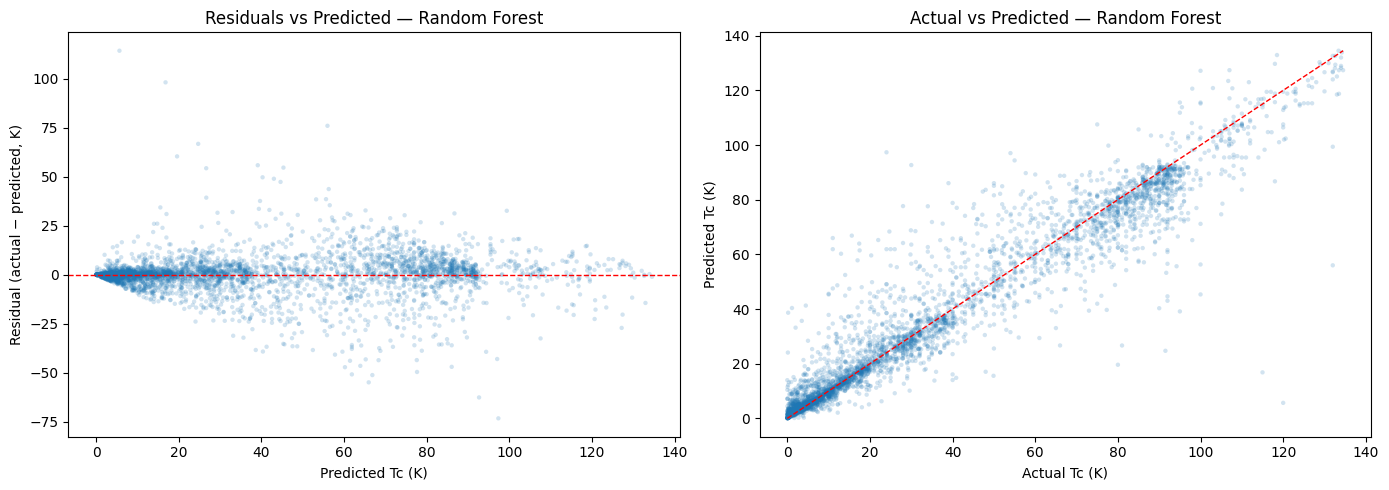

Mean residual      :  -0.046 K
Std of residuals   :   9.409 K
Most over-predicted:  -73.34 K
Most under-predict.:  114.34 K


In [58]:
import matplotlib.pyplot as plt

residuals = y_test - y_pred_rf

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Panel 1: residuals vs predicted ---
axes[0].scatter(y_pred_rf, residuals, alpha=0.2, s=10, edgecolors="none")
axes[0].axhline(0, color="red", linestyle="--", linewidth=1)
axes[0].set_xlabel("Predicted Tc (K)")
axes[0].set_ylabel("Residual (actual − predicted, K)")
axes[0].set_title("Residuals vs Predicted — Random Forest")

# --- Panel 2: actual vs predicted ---
axes[1].scatter(y_test, y_pred_rf, alpha=0.2, s=10, edgecolors="none")
lims = [min(y_test.min(), y_pred_rf.min()), max(y_test.max(), y_pred_rf.max())]
axes[1].plot(lims, lims, color="red", linestyle="--", linewidth=1)
axes[1].set_xlabel("Actual Tc (K)")
axes[1].set_ylabel("Predicted Tc (K)")
axes[1].set_title("Actual vs Predicted — Random Forest")

plt.tight_layout()
plt.show()

print(f"Mean residual      : {residuals.mean():7.3f} K")
print(f"Std of residuals   : {residuals.std():7.3f} K")
print(f"Most over-predicted: {residuals.min():7.2f} K")
print(f"Most under-predict.: {residuals.max():7.2f} K")

In [59]:
from sklearn.inspection import permutation_importance

# Compute importance by shuffling each feature and measuring the score drop
perm = permutation_importance(
    rf, X_test, y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2",
    n_jobs=-1,
)

# Organize into a readable, sorted table
importances = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False)

#print("Top 15 features by permutation importance:")
print(importances.to_string(index=False))

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


                        feature  importance_mean  importance_std
      range_ThermalConductivity         0.691720        0.014080
  wtd_gmean_ThermalConductivity         0.076060        0.004161
                std_atomic_mass         0.041722        0.001659
              wtd_gmean_Valence         0.036771        0.001342
                   mean_Density         0.017634        0.001251
       wtd_std_ElectronAffinity         0.016116        0.001404
                wtd_std_Valence         0.014340        0.000684
               wtd_mean_Valence         0.012161        0.000781
         gmean_ElectronAffinity         0.011395        0.000684
    wtd_std_ThermalConductivity         0.010453        0.000808
wtd_entropy_ThermalConductivity         0.009823        0.000577
            range_atomic_radius         0.009733        0.000810
                    std_Density         0.009042        0.000415
             entropy_FusionHeat         0.008938        0.000370
          wtd_range_atomi